In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.utils import to_categorical


In [ ]:
# Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Convert labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Class names
class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
               "Dog", "Frog", "Horse", "Ship", "Truck"]

# Hidden layers and activation functions
hidden_units = [(1024,512,256), (512,256,128),
                (256,128,64), (128,64,32)]

activations = ["relu", "tanh", "sigmoid"]

best_acc = 0
results = []

MODEL COMPARISON
[(1024, 512, 256), 'relu', 1.48760986328125, 47.33999967575073]
[(1024, 512, 256), 'tanh', 1.9236359596252441, 25.81999897956848]
[(1024, 512, 256), 'sigmoid', 1.6467909812927246, 40.389999747276306]
[(512, 256, 128), 'relu', 1.5154476165771484, 46.07999920845032]
[(512, 256, 128), 'tanh', 1.8538490533828735, 32.55000114440918]
[(512, 256, 128), 'sigmoid', 1.6710070371627808, 39.68000113964081]
[(256, 128, 64), 'relu', 1.4873614311218262, 46.03999853134155]
[(256, 128, 64), 'tanh', 1.7096894979476929, 38.909998536109924]
[(256, 128, 64), 'sigmoid', 1.6640844345092773, 39.77000117301941]
[(128, 64, 32), 'relu', 1.549074649810791, 44.67000067234039]
[(128, 64, 32), 'tanh', 1.7636826038360596, 36.59000098705292]
[(128, 64, 32), 'sigmoid', 1.717499017715454, 37.940001487731934]
[(1024, 512, 256), 'relu', 1.5240858793258667, 46.129998564720154]
[(1024, 512, 256), 'tanh', 2.0067338943481445, 21.780000627040863]
[(1024, 512, 256), 'sigmoid', 1.6608283519744873, 39.70000147819

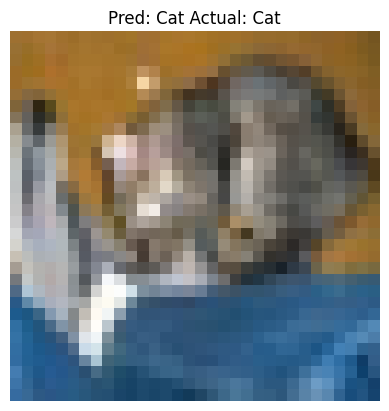

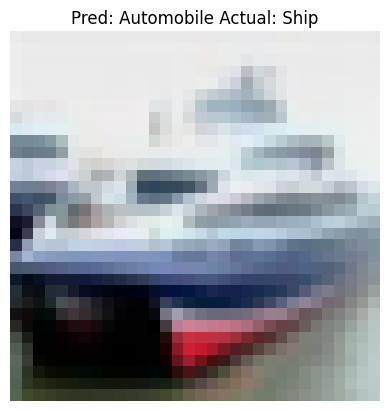

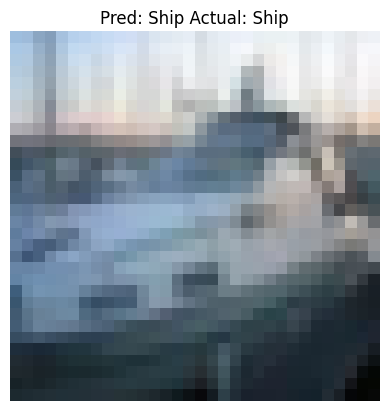

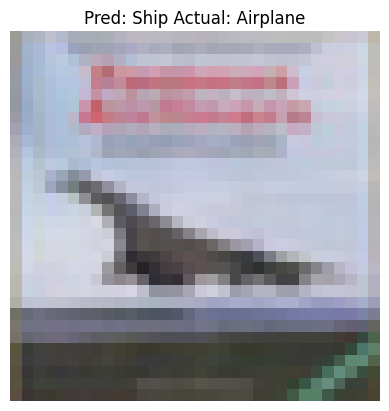

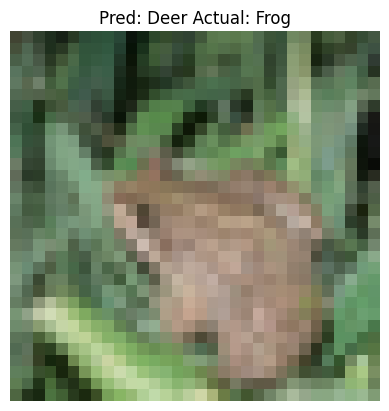

In [11]:
for units in hidden_units:
    for act in activations:

        model = Sequential([
            Input(shape=(32,32,3)),
            Flatten(),
            Dense(units[0], activation=act),
            Dense(units[1], activation=act),
            Dense(units[2], activation=act),
            Dense(10, activation="softmax")
        ])

        model.compile(optimizer="adam",
                      loss="categorical_crossentropy",
                      metrics=["accuracy"])

        model.fit(x_train, y_train, epochs=5,
                  batch_size=64, verbose=0)

        loss, acc = model.evaluate(x_test, y_test, verbose=0)

        results.append([units, act, loss, acc*100])

        if acc > best_acc:
            best_acc = acc
            best_model = model
# Display results
print("MODEL COMPARISON")

for r in results:
    print(r)

print("BEST ACCURACY:", best_acc * 100)

# Predict images

pred = best_model.predict(x_test[:5])

for i in range(5):
    predicted = pred[i].argmax()
    actual = y_test[i].argmax()

    plt.imshow(x_test[i])
    plt.title("Pred: " + class_names[predicted] + " Actual: " + class_names[actual])
    plt.axis("off")
    plt.show()